In [4]:
import pandas as pd

df = pd.read_csv("karmanta_clean.csv")
df

,Employee_ID,Age,Attrition,Business_Travel,Sub-department,Distance_From_Home,Education,Environment_Satisfaction,Gender,Salary,...,Number_of_Companies_Worked_previously,Overtime,Salary_Hike_in_percent,Total_working_years_experience,Work_life_balance,No_of_years_worked_at_current_company,No_of_years_in_current_role,Years_since_last_promotion,Native_Place,External_experience
0,1,56.0,Yes,Travel Rarely,Network Administration,24,Graduation,5,Male,186630,...,7,Yes,85,9,1,7,2,4,Hyderabad,2
1,2,46.0,Yes,Travel Rarely,Software Development,45,Degree,5,Male,78553,...,3,No,22,18,4,1,2,0,Chennai,17
2,3,32.0,No,No Travel,Data Science,30,Master's,3,Female,175003,...,2,Yes,100,5,4,5,5,8,Lucknow,0
3,4,60.0,Yes,Travel Frequently,Data Science,42,Graduation,2,Female,100795,...,5,No,72,17,2,1,7,3,Lucknow,16
4,5,25.0,No,No Travel,Network Administration,26,Graduation,4,Female,75256,...,9,No,21,12,5,7,2,4,Lucknow,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9983,9996,33.0,Yes,Travel Frequently,Data Science,35,Degree,4,Male,108566,...,5,No,68,2,2,1,4,4,Hyderabad,1
9984,9997,62.0,No,Travel Rarely,Data Science,30,Degree,5,Female,115593,...,3,Yes,55,4,1,0,1,2,Chennai,4
9985,9998,32.0,No,Travel Rarely,Data Science,44,Degree,4,Female,160923,...,1,No,87,12,5,8,0,1,Jaipur,4
9986,9999,18.0,Yes,Travel Rarely,Data Science,46,Graduation,2,Male,163365,...,9,Yes,79,10,3,8,8,3,Bengaluru,2


In [5]:
df["event"] = df["Attrition"].map({"Yes": 1, "No": 0})

In [6]:
cols = [
    "No_of_years_worked_at_current_company",  # duration
    "event",
    "Business_Travel",
    "Distance_From_Home",
    "Overtime",
    "Job_Satisfaction",
    "Environment_Satisfaction",
    "Work_life_balance",
    "Job_Involvement",
    "Years_since_last_promotion"
]

data = df[cols].copy()

In [7]:
data = pd.get_dummies(data, drop_first=True)

In [9]:
from lifelines import CoxPHFitter

cph = CoxPHFitter()
cph.fit(
    data,
    duration_col="No_of_years_worked_at_current_company",
    event_col="event"
)

<lifelines.CoxPHFitter: fitted with 9988 total observations, 7743 right-censored observations>

In [10]:
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 9988 total observations, 7743 right-censored observations>
             duration col = 'No_of_years_worked_at_current_company'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 9988
number of events observed = 2245
   partial log-likelihood = -18176.87
         time fit was run = 2026-02-11 02:43:58 UTC

---
                                    coef  exp(coef)   se(coef)   coef lower 95%   coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%
covariate                                                                                                                                 
Distance_From_Home                  0.02       1.02       0.00             0.02             0.02                 1.02                 1.02
Job_Satisfaction                   -0.12       0.89       0.02            -0.15            -0.09                 0.86                 0.91
Environment_Satisfaction           -0.27       0.76       0.02            -0.30            -0.24                 0.74                 0.78
Work_life_balance                  -0.20       0.82       0.02            -0.23            -0.17                 0.79                 0.84
Job_Involvement                    -0.22       0.80       0.02            -0.25            -0.19                 0.78                 0.83
Years_since_last_promotion          0.09       1.09       0.01             0.07             0.10                 1.07                 1.11
Business_Travel_Travel Frequently   0.54       1.72       0.06             0.41             0.67                 1.51                 1.95
Business_Travel_Travel Rarely       0.07       1.07       0.06            -0.05             0.19                 0.95                 1.20
Overtime_Yes                        0.20       1.22       0.04             0.11             0.29                 1.12                 1.33

                                    cmp to      z      p   -log2(p)
covariate                                                          
Distance_From_Home                    0.00  13.04 <0.005     126.70
Job_Satisfaction                      0.00  -7.85 <0.005      47.80
Environment_Satisfaction              0.00 -17.41 <0.005     223.03
Work_life_balance                     0.00 -13.03 <0.005     126.53
Job_Involvement                       0.00 -14.50 <0.005     155.77
Years_since_last_promotion            0.00  10.44 <0.005      82.27
Business_Travel_Travel Frequently     0.00   8.39 <0.005      54.20
Business_Travel_Travel Rarely         0.00   1.17   0.24       2.04
Overtime_Yes                          0.00   4.53 <0.005      17.36
---
Concordance = 0.70
Partial AIC = 36371.73
log-likelihood ratio test = 1203.81 on 9 df
-log2(p) of ll-ratio test = 839.58

<Axes: >

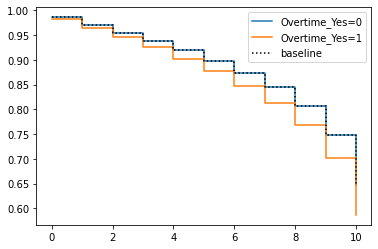

In [11]:
cph.plot_partial_effects_on_outcome(
    covariates="Overtime_Yes",
    values=[0, 1]
)